# 01 — Análise exploratória e validação do dataset sintético

Objetivos:

1. entender como o dataset sintético se parece (contas, Pix, rede, atributos);
2. **validar o gerador** contra as estatísticas públicas do Pix do Banco Central: natureza
   dos pagamentos, valores, taxa e valor das fraudes, e o que acontece com o dinheiro
   contestado (MED);
3. escolher o `eps` do DBSCAN.

Os dados do BCB são agregados por mês (não há transações individuais). O notebook gera o
dataset sintético a partir de `configs/experimento.yaml`, então não depende de `data/synthetic`.
Os arquivos do BCB são baixados na primeira execução, se ainda não existirem.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.dates import DateFormatter, MonthLocator
from matplotlib.ticker import PercentFormatter
from sklearn.neighbors import NearestNeighbors

from pixfraud.anomaly import prepare_matrix
from pixfraud.bcb import fetch
from pixfraud.experiment import load_experiment_config, prepare
from pixfraud.features import FEATURE_SETS
from pixfraud.simulation import generate_dataset, load_config, with_overrides
from pixfraud.stats import compare_groups

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CONFIG = ROOT / "configs" / "experimento.yaml"

# Aparência das figuras: tinta neutra, grade discreta, cores fixas por série.
AZUL, LARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.titlelocation": "left", "axes.titlesize": 11,
})

cfg = load_config(CONFIG)
accounts, tx = generate_dataset(cfg)


def bcb(recurso, filtro=None):
    path = ROOT / "data" / "bcb" / f"{recurso}_202506.csv"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        fetch(recurso, "202506", filter=filtro).to_csv(path, index=False)
    return pd.read_csv(path)


bcb_tx = bcb("transacoes", "AnoMes eq 202506")
bcb_fraude = bcb("fraudes").sort_values("AnoMes").reset_index(drop=True)
print(f"gerador: {len(accounts):,} contas e {len(tx):,} Pix em {cfg.n_days} dias".replace(",", "."))
print(f"BCB: {bcb_tx['QUANTIDADE'].sum():,} Pix em 06/2025; estatísticas de fraude de "
      f"{bcb_fraude['AnoMes'].min()} a {bcb_fraude['AnoMes'].max()}".replace(",", "."))

gerador: 2.142 contas e 41.993 Pix em 30 dias
BCB: 5.799.009.959 Pix em 06/2025; estatísticas de fraude de 202506 a 202604


## 1. Visão geral do dataset sintético

In [2]:
roles = accounts.set_index("account_id")["role"]
resumo = pd.DataFrame({
    "contas": accounts["role"].value_counts(),
    "fração": accounts["role"].value_counts(normalize=True).round(4),
})
display(resumo)
print(f"contas fraudulentas: {accounts['is_fraud'].mean():.2%} | Pix fraudulentos: {tx['is_fraud'].mean():.2%}")
tx["scenario"].value_counts().to_frame("Pix")

,contas,fração
role,,
normal,2000,0.9337
comercio,100,0.0467
laranja,24,0.0112
intermediario,12,0.0056
coletor,6,0.0028


contas fraudulentas: 1.96% | Pix fraudulentos: 2.12%


,Pix
scenario,
normal,41104
lavagem_em_cadeia,596
clonagem_whatsapp,121
falso_suporte,100
repasse_laranja,72


## 2. Natureza dos pagamentos e valores: gerador × BCB

No BCB, a natureza diz quem paga e quem recebe: P2P (pessoa para pessoa), P2B (pessoa para
empresa) etc. No gerador, os Pix legítimos são de pessoas (PF) para pessoas ou para
comércios (PJ); a fração que vai para comércios é o parâmetro `p_merchant`.

In [3]:
nat = bcb_tx.groupby("NATUREZA")[["VALOR", "QUANTIDADE"]].sum()
nat["ticket médio (R$)"] = nat["VALOR"] / nat["QUANTIDADE"]
nat["fração dos Pix"] = nat["QUANTIDADE"] / nat["QUANTIDADE"].sum()
display(nat.sort_values("QUANTIDADE", ascending=False).head(5)[["ticket médio (R$)", "fração dos Pix"]].round(3))

pf = bcb_tx[bcb_tx["PAG_PFPJ"] == "PF"].groupby("REC_PFPJ")["QUANTIDADE"].sum()
legit = tx[~tx["is_fraud"]]
para_comercio = legit["receiver"].map(roles).eq("comercio")
golpes = tx[tx["scenario"].isin(["falso_suporte", "clonagem_whatsapp"])]
comparacao = pd.DataFrame({
    "BCB (06/2025)": [pf["PJ"] / pf.sum(), nat.loc["P2P", "ticket médio (R$)"], nat.loc["P2B", "ticket médio (R$)"]],
    "gerador": [para_comercio.mean(), legit.loc[~para_comercio, "amount"].mean(),
                legit.loc[para_comercio, "amount"].mean()],
}, index=["fração dos Pix de PF que vão para PJ", "ticket médio P2P (R$)", "ticket médio P2B (R$)"])
comparacao.round(3)

,ticket médio (R$),fração dos Pix
NATUREZA,,
P2P,257.189,0.445
P2B,114.244,0.424
B2P,551.757,0.092
B2B,5611.114,0.034
P2G,344.126,0.002


,BCB (06/2025),gerador
fração dos Pix de PF que vão para PJ,0.490,0.395
ticket médio P2P (R$),257.189,100.989
ticket médio P2B (R$),114.244,99.379


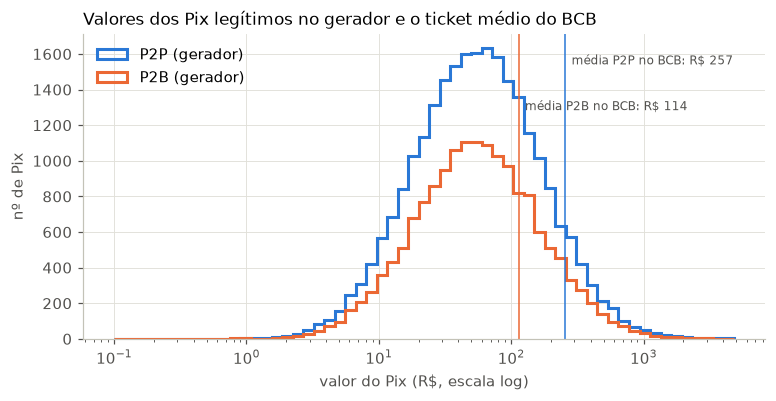

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.logspace(-1, np.log10(legit["amount"].max()), 60)
ax.hist(legit.loc[~para_comercio, "amount"], bins=bins, histtype="step", lw=2, color=AZUL, label="P2P (gerador)")
ax.hist(legit.loc[para_comercio, "amount"], bins=bins, histtype="step", lw=2, color=LARANJA, label="P2B (gerador)")
for natureza, cor in (("P2P", AZUL), ("P2B", LARANJA)):
    media = nat.loc[natureza, "ticket médio (R$)"]
    ax.axvline(media, color=cor, lw=1)
    ax.annotate(f"média {natureza} no BCB: R$ {media:.0f}", (media, ax.get_ylim()[1] * (0.9 if natureza == "P2P" else 0.75)),
                xytext=(4, 0), textcoords="offset points", fontsize=8, color="#52514e")
ax.set_xscale("log")
ax.set_xlabel("valor do Pix (R$, escala log)")
ax.set_ylabel("nº de Pix")
ax.set_title("Valores dos Pix legítimos no gerador e o ticket médio do BCB")
ax.legend(frameon=False);

**Leitura.** A fração de Pix de pessoas para empresas é parecida (49% no BCB, ~40% no
gerador), e o ticket médio P2B também (R$ 114 × R$ 99). O **P2P real é bem maior**
(R$ 257 × R$ 101): o gerador usa a mesma distribuição de valores para P2P e P2B, e o P2P
real tem uma cauda mais pesada (transferências grandes entre pessoas). Um ajuste possível
é separar os parâmetros de valor de P2P e P2B.

## 3. Fraudes: frequência e valor

O BCB publica, por mês, as contestações de Pix por fraude e o que aconteceu com o
dinheiro. Uma contestação aceita é o análogo mais próximo de um golpe do gerador.

In [5]:
golpes_por_100mil = len(golpes) / len(tx) * 1e5
ticket_golpe_bcb = bcb_fraude["ValorPixcontestadosaceitos"].sum() / bcb_fraude["Qtdecontestacoesaceitas"].sum()
pd.DataFrame({
    "BCB (média 06/2025 a 04/2026)": [bcb_fraude["Qtdecontestacoesaceitasacada100mil"].mean(), ticket_golpe_bcb,
                                      ticket_golpe_bcb / nat.loc["P2P", "ticket médio (R$)"]],
    "gerador": [golpes_por_100mil, golpes["amount"].mean(),
                golpes["amount"].mean() / legit.loc[~para_comercio, "amount"].mean()],
}, index=["golpes (contestações aceitas) a cada 100 mil Pix", "valor médio de um golpe (R$)",
          "golpe ÷ ticket médio P2P"]).round(2)

,BCB (média 06/2025 a 04/2026),gerador
golpes (contestações aceitas) a cada 100 mil Pix,4.78,526.28
valor médio de um golpe (R$),2276.94,305.00
golpe ÷ ticket médio P2P,8.85,3.02


**Leitura.** Duas diferenças grandes, as duas conhecidas:

* o gerador tem **cerca de 110 vezes** mais golpes por Pix do que o real (~530 contra ~5 a
  cada 100 mil). Foi de propósito, para haver exemplos suficientes; o cenário `realista`
  reduz isso só 3 vezes;
* os golpes reais valem ~9 vezes um Pix P2P médio (R$ 2,3 mil); no gerador, ~3 vezes. Ou
  seja, o gerador **não** exagera o valor dos golpes: se algo, subestima. O cenário
  `sem_valor` mostrou que a vantagem dos atributos de grafo não depende desse valor.

## 4. O que acontece com o dinheiro contestado (MED)

O valor contestado e aceito se divide em: devolvido (integral ou parcialmente), resto não
devolvido das devoluções parciais, e não devolvido por saldo insuficiente, conta
encerrada ou outros motivos. As parcelas somam 100% em todos os meses.

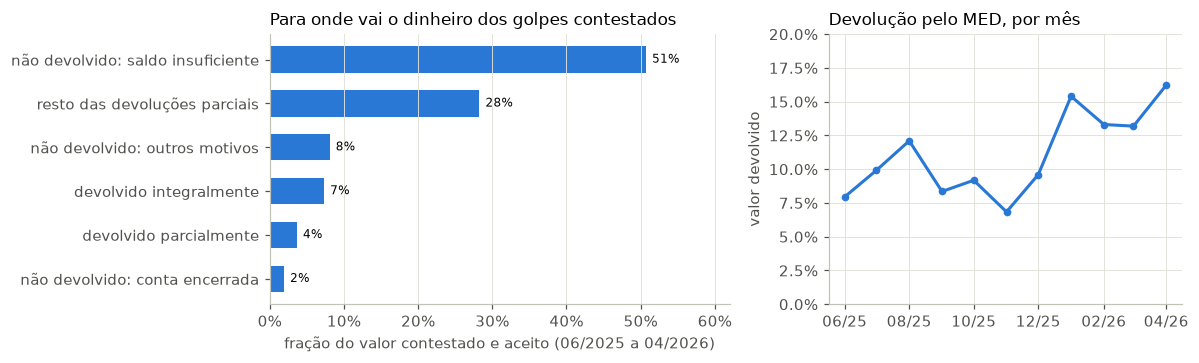

In [6]:
parcelas = {
    "devolvido integralmente": "ValorPixdevolvidosintegralmente",
    "devolvido parcialmente": "ValorPixdevolvidosparcialmente",
    "resto das devoluções parciais": "ValorPixresidualnaodevolvido",
    "não devolvido: saldo insuficiente": "ValorPixnaodevolvidossaldoinsuficiente",
    "não devolvido: conta encerrada": "Valornaodevolvidoscontaencerrada",
    "não devolvido: outros motivos": "ValorPixnaodevolvidosmotivosdiversos",
}
fracao = pd.Series({nome: bcb_fraude[col].sum() for nome, col in parcelas.items()})
fracao = fracao / bcb_fraude["ValorPixcontestadosaceitos"].sum()
assert abs(fracao.sum() - 1) < 1e-6

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.3, 1]})
ordem = fracao.sort_values()
axes[0].barh(ordem.index, ordem.values, color=AZUL, height=0.6)
for y, v in enumerate(ordem.values):
    axes[0].annotate(f"{v:.0%}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
axes[0].set_xlim(0, 0.62)
axes[0].xaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_xlabel("fração do valor contestado e aceito (06/2025 a 04/2026)")
axes[0].set_title("Para onde vai o dinheiro dos golpes contestados")
axes[0].grid(axis="y", visible=False)
meses = pd.to_datetime(bcb_fraude["AnoMes"].astype(int).astype(str), format="%Y%m")
axes[1].plot(meses, bcb_fraude["PercentualdeDevolucao"], color=AZUL, lw=2, marker="o", ms=4)
axes[1].set_ylim(0, 20)
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
axes[1].xaxis.set_major_locator(MonthLocator(interval=2))
axes[1].xaxis.set_major_formatter(DateFormatter("%m/%y"))
axes[1].set_ylabel("valor devolvido")
axes[1].set_title("Devolução pelo MED, por mês")
fig.tight_layout()

**Leitura.** Só ~11% do valor contestado volta à vítima. Metade não volta porque **o
dinheiro já saiu da conta** (saldo insuficiente), e mais ~28% é o que faltou nas
devoluções parciais. É o problema que a avaliação "detectou a tempo?"
(`scripts/04_avaliacao/avaliar_deteccao_online.py`) tenta medir: o que importa não é só achar a conta
laranja, mas achá-la **enquanto o dinheiro ainda está nela**.

## 5. Horário

Os dados do BCB não trazem o horário dos Pix. No gerador, os Pix legítimos seguem o perfil
`HOUR_WEIGHTS`. No cenário `base`, os golpes acontecem em qualquer hora (um atalho: o
`night_ratio` denuncia a fraude); com `fraud_hours: comercial`, golpes e repasses seguem o
perfil legítimo.

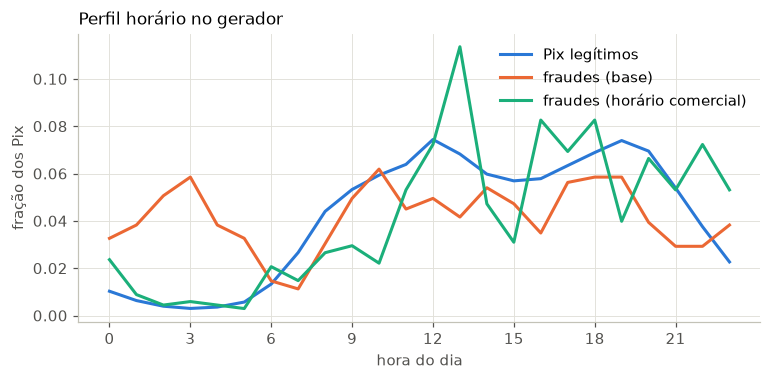

In [7]:
_, tx_comercial = generate_dataset(with_overrides(cfg, {"fraud_hours": "comercial"}))
horas = pd.DataFrame({
    "Pix legítimos": tx.loc[~tx["is_fraud"], "timestamp"].dt.hour.value_counts(normalize=True),
    "fraudes (base)": tx.loc[tx["is_fraud"], "timestamp"].dt.hour.value_counts(normalize=True),
    "fraudes (horário comercial)": tx_comercial.loc[tx_comercial["is_fraud"], "timestamp"].dt.hour.value_counts(normalize=True),
}).sort_index().fillna(0)
fig, ax = plt.subplots(figsize=(8, 3.4))
for (nome, serie), cor in zip(horas.items(), (AZUL, LARANJA, VERDE)):
    ax.plot(serie.index, serie.values, color=cor, lw=2, label=nome)
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("hora do dia")
ax.set_ylabel("fração dos Pix")
ax.set_title("Perfil horário no gerador")
ax.legend(frameon=False);

## 6. Estrutura da rede

DiGraph with 2142 nodes and 32446 edges
densidade: 0.00707 | componentes fracamente conexas: 1


agrupamento médio: 0.254


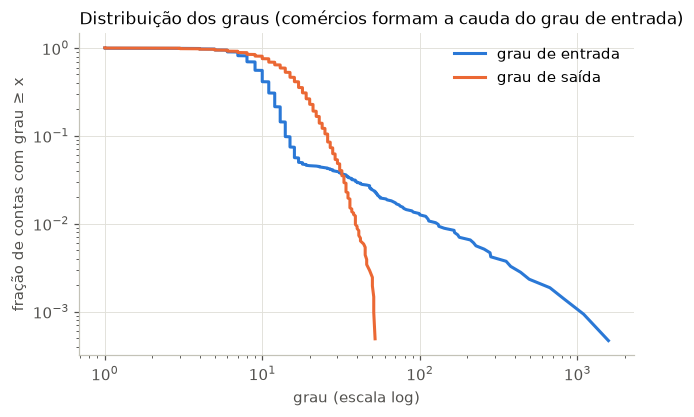

In [8]:
prepared = prepare(accounts, tx, load_experiment_config(CONFIG))
G = prepared.graph
print(G)
print(f"densidade: {nx.density(G):.5f} | componentes fracamente conexas: {nx.number_weakly_connected_components(G)}")
print(f"agrupamento médio: {nx.average_clustering(G.to_undirected()):.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for nome, graus, cor in (("grau de entrada", dict(G.in_degree()), AZUL), ("grau de saída", dict(G.out_degree()), LARANJA)):
    valores = np.sort(np.array(list(graus.values())))
    valores = valores[valores > 0]
    ccdf = 1 - np.arange(len(valores)) / len(valores)
    ax.loglog(valores, ccdf, color=cor, lw=2, label=nome)
ax.set_xlabel("grau (escala log)")
ax.set_ylabel("fração de contas com grau ≥ x")
ax.set_title("Distribuição dos graus (comércios formam a cauda do grau de entrada)")
ax.legend(frameon=False);

## 7. Atributos por papel

Quais atributos separam as contas fraudulentas das normais? Teste de Mann-Whitney com
correção de Holm e delta de Cliff (tamanho de efeito; |δ| ≥ 0,47 é grande). Com milhares
de contas quase tudo fica "significativo": o tamanho do efeito é o que importa.

In [9]:
efeitos = compare_groups(prepared.features, prepared.labels)
display(efeitos[["mediana fraude", "mediana normal", "delta de Cliff", "efeito", "p ajustado (Holm)"]].round(3))
prepared.features.groupby(roles).median().T.round(3)

,mediana fraude,mediana normal,delta de Cliff,efeito,p ajustado (Holm)
atributo,,,,,
oddball_ew,46.101,8.379,0.956,grande,0.000
avg_neighbor_degree,25.944,153.122,-0.934,grande,0.000
clustering,0.029,0.257,-0.933,grande,0.000
core_number,7.500,16.000,-0.905,grande,0.000
oddball_en,7.695,3.051,0.867,grande,0.000
out_degree,4.000,15.000,-0.862,grande,0.000
amount_received,4617.900,1156.670,0.789,grande,0.000
pagerank,0.001,0.000,0.760,grande,0.000
dwell_time_min,12.592,1564.258,-0.737,grande,0.000


role,coletor,comercio,intermediario,laranja,normal
account_age_days,27.500,2947.000,21.500,53.000,1866.500
n_sent,3.000,0.000,40.000,12.000,18.000
n_received,36.000,52.500,36.500,8.000,12.000
amount_sent,285.965,0.000,9932.885,2747.885,1761.790
amount_received,9141.615,5391.975,10255.825,2615.040,1118.080
max_amount_received,776.960,749.630,756.905,690.340,313.650
pass_through,0.031,0.000,0.973,0.941,0.505
night_ratio,0.236,0.035,0.270,0.150,0.029
dwell_time_min,6724.817,43191.083,11.112,12.592,1517.671
max_daily_in_degree,1.000,5.000,1.000,5.000,2.000


No cenário `base`, `night_ratio` e `account_age_days` aparecem com efeito grande porque
o gerador os embute por construção (ver `data/README.md`). Os cenários de dificuldade
(`scripts/04_avaliacao/avaliar_cenarios.py`) desligam esses atalhos; os resultados estão em
`docs/resultados.md`.

## 8. Escolha do `eps` do DBSCAN

Gráfico de k-distance: distância de cada conta ao `min_samples`-ésimo vizinho, em ordem
crescente. O "cotovelo" é um bom candidato a `eps`. Com `eps: auto`, o experimento usa o
quantil `eps_quantile` dessas distâncias (linha).

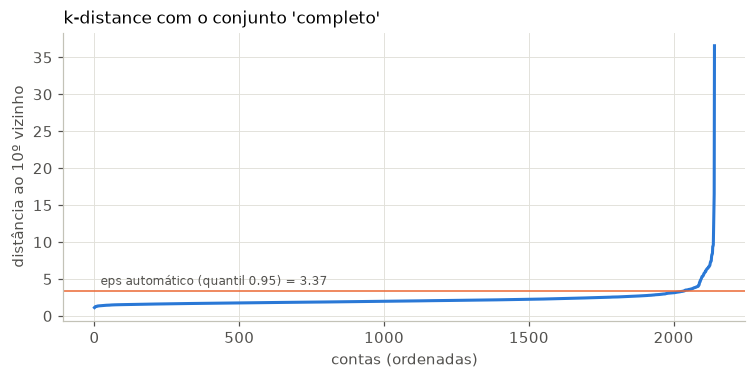

In [10]:
modelos = load_experiment_config(CONFIG)["modelos"]["dbscan"]
min_samples, quantil = modelos["min_samples"], modelos["eps_quantile"]
X = prepare_matrix(prepared.features[FEATURE_SETS["completo"]])
distancias = np.sort(NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)[0][:, -1])
eps = np.quantile(distancias, quantil)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(distancias, color=AZUL, lw=2)
ax.axhline(eps, color=LARANJA, lw=1)
ax.annotate(f"eps automático (quantil {quantil}) = {eps:.2f}", (0, eps), xytext=(4, 4), textcoords="offset points",
            fontsize=8, color="#52514e")
ax.set_xlabel("contas (ordenadas)")
ax.set_ylabel(f"distância ao {min_samples}º vizinho")
ax.set_title("k-distance com o conjunto 'completo'");

## 9. O que ajustar no gerador

| Aspecto | BCB | Gerador | Sugestão |
|---|---|---|---|
| Pix de PF para PJ | ~49% | ~40% | `p_merchant: 0.49` |
| Ticket médio P2P | ~R$ 257 | ~R$ 101 | parâmetros de valor separados para P2P e P2B |
| Golpes a cada 100 mil Pix | ~5 | ~530 | manter alto para ter exemplos, mas reportar sempre a taxa; testar taxas menores |
| Valor do golpe ÷ ticket P2P | ~9 | ~3 | `fraud_amount_shift` maior é plausível; `sem_valor` mostra que a conclusão não depende disso |
| Dinheiro devolvido pelo MED | ~11% | — | referência para a métrica de dinheiro recuperável |

Fontes: `data/bcb/transacoes_202506.csv` e `data/bcb/fraudes_202506.csv` (dados abertos do
Pix, Banco Central do Brasil), baixados com `scripts/01_dados/baixar_dados_bcb.py`.